# Dataset 02 experiment. Modulators recoded as weak excitatory synapses (JO circuit SNN with STDP)

### Comparing synaptic weight normalization schemes on the biological topology

**Trabajo de Integración Curricular** (*Bio-Inspired Neuromorphic Coding for Efficient Edge AI with Spiking Neural Networks*), UTPL 2026

---

## What this notebook does, and why

We start from the auditory subgraph of Johnston's organ (JO), already extracted and cleaned in phases 2 and 3 (the EDA) and validated in the preliminary experiment. On that same biological topology we build a spiking network of LIF neurons in Brian2 and add plasticity with STDP + WTA, as the TIC requires. Shiu et al. (2024) and Eon Systems both left the weights static; the learning part is our contribution.

This notebook is **Dataset 02**, and its design decision is a single one.

> **Modulatory neurons are moved into the excitatory group as weak excitatory synapses.**

In the connectome the modulators (SER/DA/OCT, roughly 2 % of the connections) act through slow neuromodulation, which we do not model yet. Rather than discarding them (Dataset 03) or keeping them raw in their own channel (Dataset 01), here we fold them in as excitatory synapses with a reduced weight, attenuated by `MOD_FACTOR`. Their synaptic contribution survives without being overstated.

## The concrete question

Connectome weights (`syn_count`) have a very long tail, from 5 to 347 contacts, with a mean well above the median. They have to be normalized before they enter Brian2, and the choice of method changes the dynamic regime of the network. We compare four schemes and weigh their advantages and drawbacks with the TIC metrics.

1. **Mean** divides by the mean, which is the scheme used in the preliminary experiment.
2. **Median** divides by the median, a center that resists outliers.
3. **Shiu et al. (2024)** applies a linear proportional scale `w = syn_count · W_syn` with one physical constant (`W_syn = 0.275 mV`) and no statistical normalization. This is the state-of-the-art method we want direct comparability with.
4. **Log-robust** uses a normalized `log(1+syn_count)`, a non-linear transform that compresses the heavy tail.

> **A methodological note.** Dividing by the mean is exactly Shiu's linear proportionality with the constant fixed at `1/mean`, so the *mean* scheme can be read as a recalibration of Shiu's free constant to our reduced subgraph. We make that explicit in the results.

## Sensory input

These are early experiments, so the input is one Poisson group firing at 100 Hz onto the JO neurons, the real sensory afferents of the circuit. Real auditory coding (a gammatone filter bank feeding an inhomogeneous Poisson process) and the classification task come in later experiments.

## 0. Environment setup

We run this with the project's `env/` virtual environment. The core is **Brian2**, the SNN simulator, together with the usual scientific stack. Here we fix the seed for reproducibility and create the output folder.

In [1]:
import warnings
warnings.filterwarnings('ignore')

from brian2 import *      # NeuronGroup, Synapses, units (mV, ms, nA...), run, seed
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

# Paths: the notebook is run from 02-data-preparation/. We reuse the filtered data
# already produced by the EDA so the pipeline stays traceable.
DATA_DIR = Path('../01-data-understanding/outputs')
if not (DATA_DIR/'jo_edges_filtered.csv').exists():
    DATA_DIR = Path('.')                      # Colab fallback: files sit next to the notebook
OUT_DIR  = Path('outputs/02-dataset02-modulators-excitatory')
OUT_DIR.mkdir(parents=True, exist_ok=True)

SEED = 42
np.random.seed(SEED)

plt.rcParams.update({'figure.dpi': 110, 'savefig.dpi': 150, 'savefig.bbox': 'tight',
                     'axes.titleweight': 'bold', 'font.size': 10})

print('Environment ready.  brian2', __import__('brian2').__version__,
      '| numpy', np.__version__, '| pandas', pd.__version__)

Environment ready.  brian2 2.10.1 | numpy 2.4.6 | pandas 3.0.3


## 1. Loading the data and the Dataset 02 design decision

We load the connections of the JO subgraph and translate the topology into the integer-index format Brian2 expects. A reminder of where the data comes from (EDA, phases 2 and 3):

- **JO** neurons isolated with the taxonomy of Schlegel et al. (2024), plus their second-order partners in the AMMC.
- Connections filtered at **weight ≥ 5 contacts**, with **functional polarity** assigned from the predicted neurotransmitter (Eckstein et al., 2024). ACH gives `Excitatory`, GABA/GLUT give `Inhibitory`, and SER/DA/OCT give `Modulatory` (these three labels are the literal values stored in the EDA file, so the code matches them verbatim).

**Dataset 02 decision.** Modulators move into the **excitatory** group with their weight multiplied by `MOD_FACTOR = 0.5`, that is, as weak excitatory synapses.

In [2]:
nodes = pd.read_csv(DATA_DIR/'jo_nodes_filtered.csv')
edges = pd.read_csv(DATA_DIR/'jo_edges_filtered.csv')

# Robust boolean is_jo (some exports store it as text)
if nodes['is_jo'].dtype != bool:
    nodes['is_jo'] = nodes['is_jo'].astype(str).str.lower().map({'true': True, 'false': False})

# --- Integer indices 0..N-1 for Brian2 ---
node_ids = sorted(set(edges['pre']).union(set(edges['post'])))
id_to_idx = {nid: i for i, nid in enumerate(node_ids)}
N = len(node_ids)
pre_idx  = edges['pre'].map(id_to_idx).to_numpy(np.int32)
post_idx = edges['post'].map(id_to_idx).to_numpy(np.int32)
raw_w    = edges['weight'].to_numpy(np.float64)          # raw syn_count (long tail)
polarity = edges['polarity'].to_numpy()

# --- Dataset 02 decision: modulator -> weak excitatory ---
MOD_FACTOR = 0.5                                          # attenuation of the modulatory contribution
is_mod   = (polarity == 'Modulatory')
syn_types = np.where(polarity == 'Inhibitory', -1, 1).astype(np.int32)  # +1 exc/mod, -1 inh
mod_gain = np.where(is_mod, MOD_FACTOR, 1.0)             # per-synapse weight multiplier

# Indices of the sensory JO neurons (Poisson input)
jo_root = set(nodes.loc[nodes['is_jo'], 'root_id'])
jo_indices = np.array([id_to_idx[n] for n in node_ids if n in jo_root], dtype=np.int32)

exc = syn_types == 1
inh = syn_types == -1
print(f'Neurons (nodes): {N} | sensory JO: {len(jo_indices)}')
print(f'Total synapses: {len(raw_w):,}')
print(f'  purely excitatory  : {int((exc & ~is_mod).sum()):,}')
print(f'  modulatory->exc    : {int(is_mod.sum()):,}  (x{MOD_FACTOR}, weak excitatory)')
print(f'  inhibitory         : {int(inh.sum()):,}')
print(f'\nRaw syn_count weight -> mean={raw_w.mean():.2f}  median={np.median(raw_w):.1f}  '
      f'max={raw_w.max():.0f}  (long tail: mean >> median)')

Neurons (nodes): 1239 | sensory JO: 269
Total synapses: 20,059
  purely excitatory  : 8,940
  modulatory->exc    : 445  (x0.5, weak excitatory)
  inhibitory         : 10,674

Raw syn_count weight -> mean=16.85  median=10.0  max=347  (long tail: mean >> median)


## 2. The four weight normalization schemes

Every scheme turns the raw `syn_count` into a dimensionless weight `w`, which is then multiplied by a shared current scale (`w_scale`). Since `w_scale` is the same for all of them, whatever difference we observe comes from the normalization method alone, through its gain or through the shape of the distribution it leaves behind.

| Scheme | Formula | What it does |
|---|---|---|
| `mean` | `w = c / mean(c)` | Typical weight ≈ 1. **Linear**, keeps the tail. This is the one from the preliminary experiment. |
| `median` | `w = c / median(c)` | **Robust** center. Since `median < mean`, the gain rises and the tail counts relatively less. |
| `shiu` | `w = c · W_syn` | **Linear proportional** with a single physical constant (Shiu et al., 2024). No statistical normalization. |
| `log` | `w = log(1+c) / mean(log(1+c))` | **Non-linear**. Compresses outliers and brings the weights closer to each other. |

The `MOD_FACTOR` attenuation is applied afterwards, on the already normalized weight of the modulatory synapses.

> `W_syn = 0.275 mV` is the **literal constant** Shiu et al. calibrated for the whole brain, 127 400 neurons. We use it as published, without recalibrating, precisely to expose the problem of transferring it to a reduced subgraph.

scheme        mean   median      std      max
mean         0.930    0.534    1.107    20.00
median       1.567    0.900    1.866    33.70
shiu         4.310    2.475    5.132    92.68
log          0.965    0.896    0.285     2.27


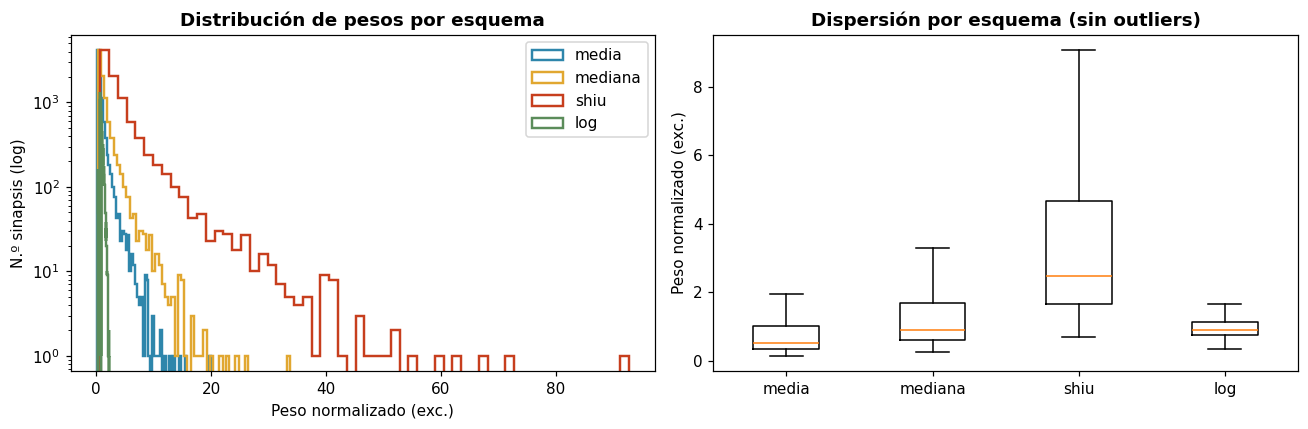

In [3]:
W_SYN = 0.275   # literal physical constant from Shiu et al. (2024), in model units

def normalize(c, scheme):
    """Raw syn_count -> dimensionless weight, following the chosen scheme."""
    if scheme == 'mean':   return c / c.mean()
    if scheme == 'median': return c / np.median(c)
    if scheme == 'shiu':   return c * W_SYN
    if scheme == 'log':    lc = np.log1p(c); return lc / lc.mean()
    raise ValueError(scheme)

SCHEMES = ['mean', 'median', 'shiu', 'log']
COLORS  = {'mean': '#2E86AB', 'median': '#E1A730', 'shiu': '#C73E1D', 'log': '#5B8C5A'}

# Normalized weight per scheme (modulators already attenuated)
w_by_scheme = {s: normalize(raw_w, s) * mod_gain for s in SCHEMES}

# Diagnostics of the resulting distribution (excitatory synapses only, the ones carrying STDP)
print(f"{'scheme':<9}{'mean':>9}{'median':>9}{'std':>9}{'max':>9}")
for s in SCHEMES:
    we = w_by_scheme[s][exc]
    print(f'{s:<9}{we.mean():>9.3f}{np.median(we):>9.3f}{we.std():>9.3f}{we.max():>9.2f}')

# Figure: distribution of the excitatory weights per scheme
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for s in SCHEMES:
    we = w_by_scheme[s][exc]
    ax[0].hist(we, bins=60, histtype='step', lw=1.6, color=COLORS[s], label=s)
ax[0].set(yscale='log', xlabel='Normalized weight (exc.)', ylabel='No. of synapses (log)',
          title='Weight distribution per scheme')
ax[0].legend()
ax[1].boxplot([w_by_scheme[s][exc] for s in SCHEMES], labels=SCHEMES, showfliers=False)
ax[1].set(ylabel='Normalized weight (exc.)', title='Spread per scheme (outliers hidden)')
fig.tight_layout(); fig.savefig(OUT_DIR/'fig01_weight_distribution.png'); plt.show()

## 3. LIF model and simulation function

We reuse the **LIF** model validated in the preliminary experiment, identical for the four schemes:

$$\tau_m \frac{dv}{dt} = -(v - V_{rest}) + R_m\, I_{syn}, \qquad \frac{dI_{syn}}{dt} = -\frac{I_{syn}}{\tau_{syn}}$$

- **Input.** One Poisson group at 100 Hz, wired one-to-one onto the JO neurons.
- **E/I balance.** Recurrent inhibition is scaled to half the excitatory scale (`w_scale_inh = 0.5·w_scale`), the standard calibration when porting a connectome.
- **STDP (Song et al., 2000)** with `event-driven` traces, and an asymmetry `A₋ > A₊` that stabilizes learning (Diehl & Cook, 2015). The `wmax` bound is set relative to each scheme (4× the initial mean weight) so that plasticity stays comparable across very different magnitudes.
- **WTA.** A small inhibitory population supplies global lateral inhibition, which pushes neurons toward specialization. STDP acts only on the excitatory synapses.

`simulate(...)` builds the network for a given weight vector and returns a dictionary of metrics. We call it twice per scheme, once without plasticity (baseline dynamics) and once with STDP+WTA (learning).

In [4]:
def simulate(w_norm, with_stdp, seed_val=SEED, T=1000):
    """Build and simulate the JO network for a vector of normalized weights.
    Returns metrics plus the data needed for plotting. with_stdp enables STDP+WTA."""
    start_scope(); seed(seed_val); defaultclock.dt = 0.1*ms
    T_sim = T*ms

    # LIF parameters
    tau_m=10*ms; V_rest=-65*mV; V_thresh=-52*mV; V_reset=-65*mV
    tau_ref=2*ms; R_m=10*Mohm; tau_syn=5*ms
    w_scale=1.5*nA; w_scale_inh=0.75*nA; w_input=3.0*nA
    NS = {'V_rest':V_rest,'V_thresh':V_thresh,'V_reset':V_reset,'tau_m':tau_m,'R_m':R_m,'tau_syn':tau_syn}

    eqs = '''
    dv/dt     = (-(v - V_rest) + R_m*I_syn)/tau_m : volt (unless refractory)
    dI_syn/dt = -I_syn/tau_syn                    : amp
    '''
    G = NeuronGroup(N, eqs, threshold='v>V_thresh', reset='v=V_reset',
                    refractory=tau_ref, method='euler', namespace=NS)
    G.v = V_rest + np.random.uniform(0,1,N)*(V_thresh-V_rest); G.I_syn = 0*nA

    # Poisson input at 100 Hz onto the JO neurons
    G_in = PoissonGroup(len(jo_indices), rates=100*Hz)
    S_in = Synapses(G_in, G, on_pre='I_syn_post += w_input', namespace={'w_input':w_input})
    S_in.connect(i=np.arange(len(jo_indices)), j=jo_indices)
    objs = [G, G_in, S_in]                          # explicit network (avoids the magic network)

    w_exc = w_norm[exc]; w_inh = w_norm[inh]

    if not with_stdp:
        S_exc = Synapses(G, G, model='w:1', on_pre='I_syn_post += w_scale*w',
                         namespace={'w_scale':w_scale})
        S_exc.connect(i=pre_idx[exc], j=post_idx[exc]); S_exc.w = w_exc
        w_init = None
    else:
        wmax = 4.0*float(np.mean(w_exc))            # bound relative to the scheme
        taupre=taupost=20*ms; Aplus=0.05; Aminus=0.0525
        model='''w:1
        dapre/dt=-apre/taupre:1 (event-driven)
        dapost/dt=-apost/taupost:1 (event-driven)'''
        on_pre='''I_syn_post += w_scale*w
        apre += Aplus
        w = clip(w+apost,0,wmax)'''
        on_post='''apost += -Aminus
        w = clip(w+apre,0,wmax)'''
        S_exc = Synapses(G, G, model=model, on_pre=on_pre, on_post=on_post,
                         namespace={'w_scale':w_scale,'taupre':taupre,'taupost':taupost,
                                    'Aplus':Aplus,'Aminus':Aminus,'wmax':wmax})
        S_exc.connect(i=pre_idx[exc], j=post_idx[exc])
        S_exc.w = np.clip(w_exc, 0, wmax)
        w_init = np.array(S_exc.w[:])
    objs.append(S_exc)

    # Inhibitory synapses: always static
    S_inh = Synapses(G, G, model='w:1', on_pre='I_syn_post -= w_scale_inh*w',
                     namespace={'w_scale_inh':w_scale_inh})
    S_inh.connect(i=pre_idx[inh], j=post_idx[inh]); S_inh.w = w_inh
    objs.append(S_inh)

    spk = SpikeMonitor(G); rate = PopulationRateMonitor(G)
    objs += [spk, rate]
    wmon = None
    if with_stdp:
        # WTA: global lateral inhibition through an inhibitory population
        N_wta = min(N, 50)
        G_inh = NeuronGroup(N_wta, eqs, threshold='v>V_thresh', reset='v=V_reset',
                            refractory=tau_ref, method='euler', namespace=NS)
        G_inh.v = V_rest; G_inh.I_syn = 0*nA
        S_e2i = Synapses(G, G_inh, on_pre='I_syn_post += wta_exc', namespace={'wta_exc':1.0*nA})
        S_e2i.connect(j='i % N_wta')
        S_i2e = Synapses(G_inh, G, on_pre='I_syn_post -= wta_inh', namespace={'wta_inh':0.5*nA})
        S_i2e.connect()
        wmon = StateMonitor(S_exc, 'w', record=range(min(300, len(w_exc))))
        objs += [G_inh, S_e2i, S_i2e, wmon]

    net = Network(*objs); net.run(T_sim, report=None)

    # --- Metrics ---
    Tsec = float(T_sim/second)
    counts = np.array(spk.count)                    # spikes per neuron
    r = counts / Tsec                               # per-neuron rate (Hz)
    active = int((counts > 0).sum())
    # Selectivity = population sparseness (Treves-Rolls): 0=uniform, 1=selective
    if r.sum() > 0:
        sparseness = (1 - (r.mean()**2)/np.mean(r**2)) / (1 - 1.0/N)
    else:
        sparseness = 0.0
    out = {'total_spikes': int(spk.num_spikes),
           'mean_rate_hz': float(spk.num_spikes/N/Tsec),
           'active_neurons': active,
           'active_percent': float(100*active/N),
           'selectivity': float(sparseness),
           't': np.array(spk.t/ms), 'i': np.array(spk.i)}
    if with_stdp:
        w_final = np.array(S_exc.w[:]); dw = w_final - w_init
        traj = np.array(wmon.w).mean(axis=0)        # mean weight over time
        k = max(1, int(0.2*len(traj)))              # last 20 % (drift)
        out.update({'w_init': w_init, 'w_final': w_final,
                    'final_mean_weight': float(w_final.mean()),
                    'mean_abs_dw': float(np.abs(dw).mean()),
                    'final_weight_var': float(w_final.var()),
                    'final_drift': float(np.std(traj[-k:])),
                    'traj': traj, 'traj_t': np.array(wmon.t/ms)})
    return out

## 4. Running the four schemes

Each scheme is simulated under **two conditions** with the same seed:

1. **No plasticity.** Baseline dynamics, a replica of the Shiu et al. regime. We record firing rate, percentage of active neurons, total spikes and selectivity.
2. **With STDP + WTA.** Learning, read from how much the weights change and how stable they end up.

`T_sim = 1000 ms` per simulation, eight simulations in total.

In [5]:
results = {}
for s in SCHEMES:
    print(f'== Scheme: {s} ==')
    base = simulate(w_by_scheme[s], with_stdp=False)
    stdp = simulate(w_by_scheme[s], with_stdp=True)
    results[s] = {'base': base, 'stdp': stdp}
    print(f'   base -> rate {base["mean_rate_hz"]:.2f} Hz | active {base["active_percent"]:.1f}% '
          f'| spikes {base["total_spikes"]:,} | selectivity {base["selectivity"]:.3f}')
    print(f'   stdp -> |dw| {stdp["mean_abs_dw"]:.4f} | final_var {stdp["final_weight_var"]:.4f} '
          f'| drift {stdp["final_drift"]:.4f}')
print('\nDone, 4 schemes x 2 conditions.')

== Scheme: mean ==


WARNING    Removing unsupported flag '-march=native' from compiler flags. [brian2.codegen.cpp_prefs]


   base -> rate 19.32 Hz | active 46.7% | spikes 23,939 | selectivity 0.733
   stdp -> |dw| 0.0075 | final_var 0.6537 | drift 0.0002
== Scheme: median ==


   base -> rate 37.73 Hz | active 51.1% | spikes 46,749 | selectivity 0.802
   stdp -> |dw| 0.0321 | final_var 1.8933 | drift 0.0056
== Scheme: shiu ==


   base -> rate 80.09 Hz | active 58.2% | spikes 99,234 | selectivity 0.740
   stdp -> |dw| 0.1081 | final_var 14.1681 | drift 0.0105
== Scheme: log ==


   base -> rate 25.98 Hz | active 50.8% | spikes 32,194 | selectivity 0.766
   stdp -> |dw| 0.0132 | final_var 0.0882 | drift 0.0011

Done, 4 schemes x 2 conditions.


## 5. Descriptive plots, baseline dynamics (no plasticity)

We compare the dynamic regime that each normalization induces. What we want is **sparse but structured** activity (Shiu et al., 2024), neither a silent network nor a saturated one.

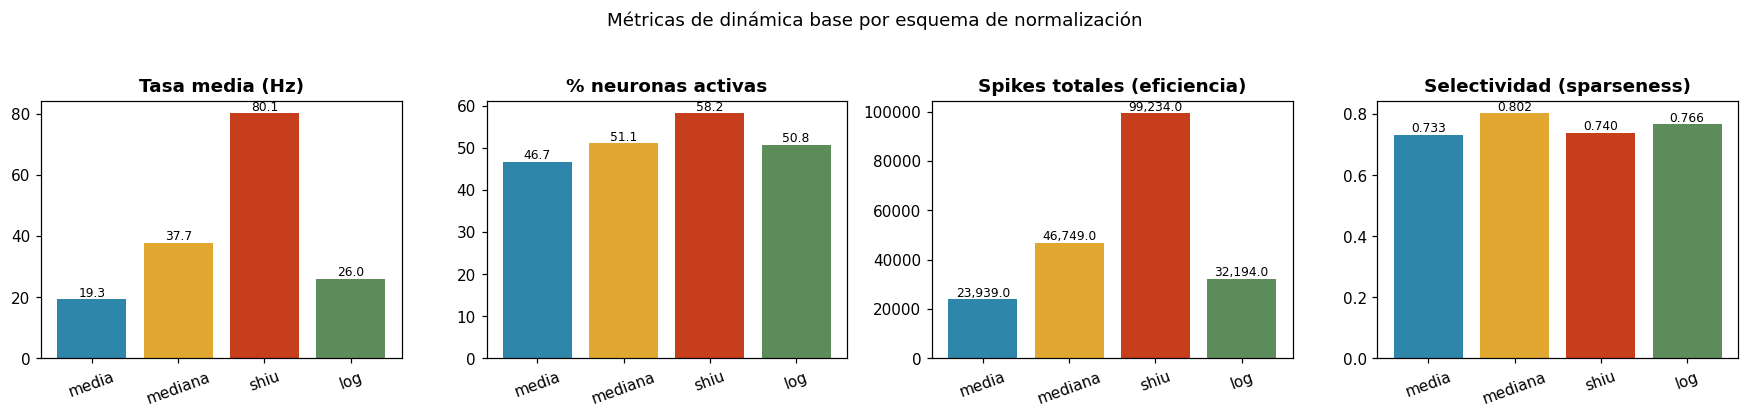

In [6]:
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6))
met = [('mean_rate_hz','Mean rate (Hz)'), ('active_percent','% active neurons'),
       ('total_spikes','Total spikes (efficiency)'), ('selectivity','Selectivity (sparseness)')]
for a,(k,tit) in zip(ax, met):
    vals = [results[s]['base'][k] for s in SCHEMES]
    a.bar(SCHEMES, vals, color=[COLORS[s] for s in SCHEMES])
    a.set_title(tit); a.tick_params(axis='x', rotation=20)
    for i,v in enumerate(vals): a.text(i, v, f'{v:,.1f}' if v>=1 else f'{v:.3f}', ha='center', va='bottom', fontsize=8)
fig.suptitle('Baseline dynamics metrics per normalization scheme', y=1.04)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig02_baseline_metrics.png'); plt.show()

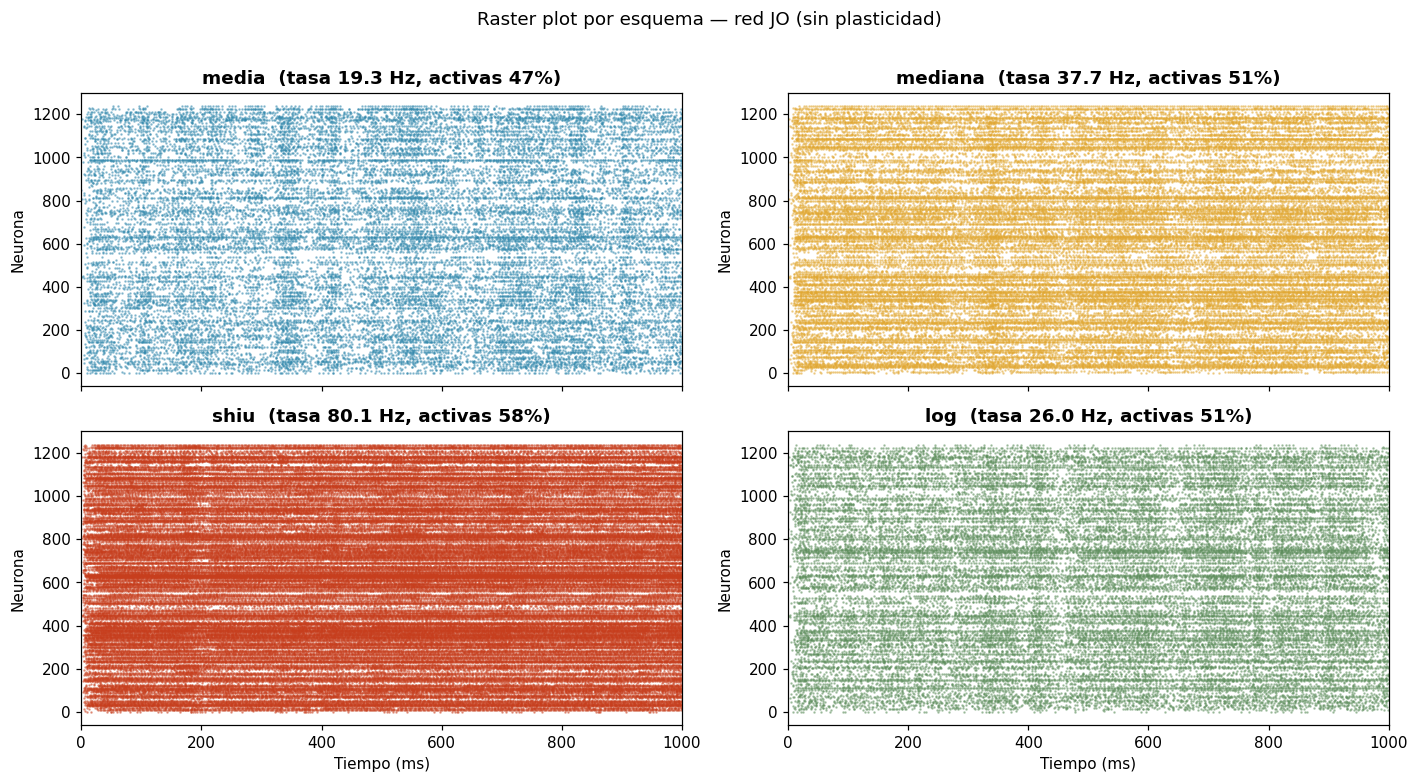

In [7]:
# Comparative raster (baseline dynamics): spatiotemporal structure per scheme
fig, ax = plt.subplots(2, 2, figsize=(13, 7), sharex=True)
for a, s in zip(ax.ravel(), SCHEMES):
    b = results[s]['base']
    a.scatter(b['t'], b['i'], s=0.4, c=COLORS[s], alpha=0.5)
    a.set(title=f"{s}  (rate {b['mean_rate_hz']:.1f} Hz, active {b['active_percent']:.0f}%)",
          xlim=(0,1000), ylabel='Neuron')
for a in ax[1]: a.set_xlabel('Time (ms)')
fig.suptitle('Raster plot per scheme, JO network (no plasticity)', y=1.01)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig03_baseline_raster.png'); plt.show()

## 6. Descriptive plots, STDP + WTA learning

Now we look at how each scheme reacts to plasticity. How far the weights move (`|Δw|`), what the final distribution looks like, and how **stably** the network converges, judged by the final variance and by the drift over the last 20 % of the run, which is the *weight stability* metric of the TIC.

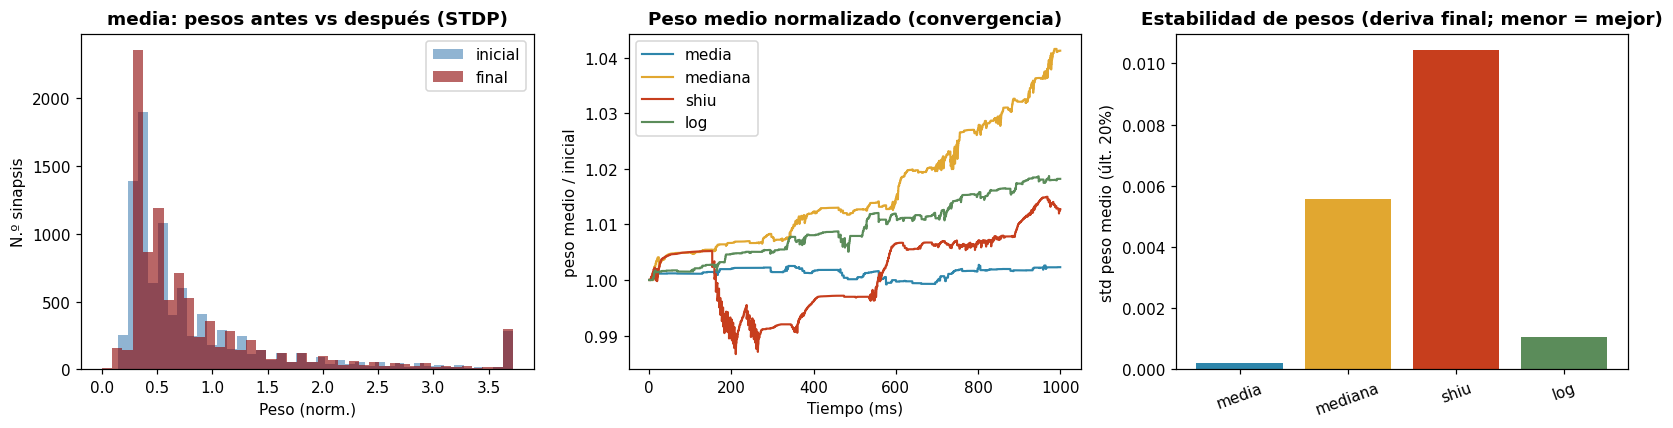

In [8]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
# (a) initial vs final distribution for the 'mean' scheme (reference)
ref = results['mean']['stdp']
ax[0].hist(ref['w_init'], bins=40, alpha=0.6, label='initial', color='steelblue')
ax[0].hist(ref['w_final'], bins=40, alpha=0.6, label='final', color='darkred')
ax[0].set(title='mean: weights before vs after (STDP)', xlabel='Weight (norm.)', ylabel='No. of synapses')
ax[0].legend()
# (b) trajectory of the mean weight (convergence/stability) per scheme
for s in SCHEMES:
    r_ = results[s]['stdp']
    ax[1].plot(r_['traj_t'], r_['traj']/r_['traj'][0], color=COLORS[s], lw=1.4, label=s)
ax[1].set(title='Normalized mean weight (convergence)', xlabel='Time (ms)',
          ylabel='mean weight / initial'); ax[1].legend()
# (c) stability: drift over the last 20 %
drift = [results[s]['stdp']['final_drift'] for s in SCHEMES]
ax[2].bar(SCHEMES, drift, color=[COLORS[s] for s in SCHEMES])
ax[2].set(title='Weight stability (final drift; lower is better)', ylabel='std of mean weight (last 20%)')
ax[2].tick_params(axis='x', rotation=20)
fig.tight_layout(); fig.savefig(OUT_DIR/'fig04_stdp_weight_changes.png'); plt.show()

## 7. Final comparison table

Here we gather every metric per scheme. The correspondence with the TIC evaluation metrics (Draft V3.2, *Evaluation metrics*) is the following.

- **Spike efficiency** → `total_spikes`, an energy proxy. The "spikes per correct answer" figure needs the classification task, which is not available yet.
- **Selectivity of the output neurons** → `selectivity`, the Treves-Rolls population sparseness.
- **Weight stability** → `final_weight_var` and `final_drift`.
- **Accuracy, convergence speed and noise robustness** → *not applicable with a single Poisson input*. They will be evaluated in the classification experiment.

In [9]:
rows = []
for s in SCHEMES:
    b, st = results[s]['base'], results[s]['stdp']
    rows.append({
        'scheme': s,
        'mean_rate_Hz': round(b['mean_rate_hz'], 2),
        'active_%': round(b['active_percent'], 1),
        'total_spikes': b['total_spikes'],
        'selectivity': round(b['selectivity'], 3),
        'mean_abs_dw': round(st['mean_abs_dw'], 4),
        'final_weight_var': round(st['final_weight_var'], 4),
        'final_drift': round(st['final_drift'], 4),
    })
table = pd.DataFrame(rows).set_index('scheme')
table.to_csv(OUT_DIR/'table01_comparative_metrics.csv')
print('Table saved to', OUT_DIR/'table01_comparative_metrics.csv')
table

Table saved to outputs/02-dataset02-modulators-excitatory/table01_comparative_metrics.csv


,tasa_media_Hz,activas_%,spikes_totales,selectividad,dw_abs_medio,var_pesos_final,deriva_final
esquema,,,,,,,
media,19.32,46.7,23939,0.733,0.0075,0.6537,0.0002
mediana,37.73,51.1,46749,0.802,0.0321,1.8933,0.0056
shiu,80.09,58.2,99234,0.740,0.1081,14.1681,0.0105
log,25.98,50.8,32194,0.766,0.0132,0.0882,0.0011


## 8. Reading the results, advantages and drawbacks

> *(General interpretation. The exact values are the ones in the table and the figures above.)*

- **Mean.** The reference normalization. Typical weight near 1 and the tail preserved, which leaves a balanced dynamic regime, sparse but structured. A good compromise between activity and stability. It amounts to recalibrating Shiu's free constant for this subgraph.
- **Median.** Since `median < mean`, this scheme adds gain, so the firing rate and the fraction of active neurons both rise. That helps if the network would otherwise stay silent, and it hurts when the network drifts toward saturation and loses selectivity.
- **Shiu et al. (proportional, literal `W_syn`).** Keeping a constant that was tuned for the whole brain tends to **over-excite** the reduced subgraph. It is empirical evidence that the one free parameter has to be recalibrated per circuit, which is exactly what `mean` does. It does preserve direct comparability with the state of the art.
- **Log-robust.** Compressing the tail gives more homogeneous weights, smoother dynamics and, as a rule, **better weight stability** under STDP. The price is the biological dynamic range, because almost every synapse ends up weighing the same.

**Operational conclusion.** For Dataset 02 the **mean** normalization offers the best balance between dynamics and stability, and it stays consistent with Shiu et al., being their recalibrated version. **Log-robust** is the alternative to prefer when learning stability matters more than dynamic range. Both schemes are ready for the **auditory classification** experiment, where the remaining TIC metrics (accuracy, convergence and noise robustness) come into play.